# Linear dependence and independence

## Dependent

The vectors are linearly dependent if there exist scalars $c_1, c_2, \dots, c_k$, not all zero, such that

$$
c_1 v_1 + c_2 v_2 + \cdots + c_k v_k = 0.
$$

In plain words: at least one vector can be written as a combination of the others. Geometrically, they are "redundant" — they don't point in enough new directions.

## Independent

The vectors are linearly independent if the only solution to

$$
c_1 v_1 + c_2 v_2 + \cdots + c_k v_k = 0
$$

is

$$
c_1 = c_2 = \cdots = c_k = 0.
$$

In plain words: no vector can be built from the others. Each one adds a genuinely new direction.

## Concluding

Dependent $\iff$ one is a scalar multiple of the other $\iff$ $v_1 = \lambda v_2$ for some $\lambda$.

Independent $\iff$ they are not scalar multiples.

In $\mathbb{R}^3$, this is equivalent to $v_1 \times v_2 \neq 0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def plot_2d(v1, v2, title=""):
    v1 = np.array(v1, dtype=float)
    v2 = np.array(v2, dtype=float)
    cross = v1[0]*v2[1] - v1[1]*v2[0]
    dependent = abs(cross) < 1e-9

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)

    # Draw lines through origin in the direction of each vector
    t = np.linspace(-3, 3, 100)
    ax.plot(t*v1[0], t*v1[1], color='blue', alpha=0.3, linestyle='--')
    ax.plot(t*v2[0], t*v2[1], color='red',  alpha=0.3, linestyle='--')

    # Draw the arrows
    ax.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1,
              color='blue', width=0.012, label='v1')
    ax.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1,
              color='red', width=0.012, label='v2')

    if dependent:
        ax.set_title(title + "\nDEPENDENT (same line)")
    else:
        ax.set_title(title + "\nINDEPENDENT (span the plane)")

    m = max(3, 1.2*np.max(np.abs([v1, v2])))
    ax.set_xlim(-m, m); ax.set_ylim(-m, m)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

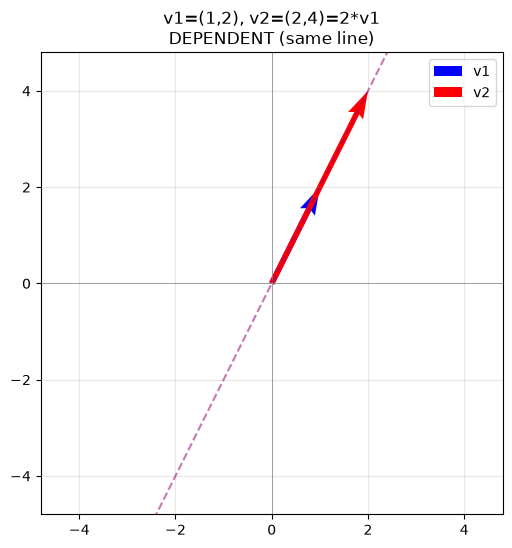

In [3]:
# Dependent example
plot_2d([1, 2], [2, 4], "v1=(1,2), v2=(2,4)=2*v1")

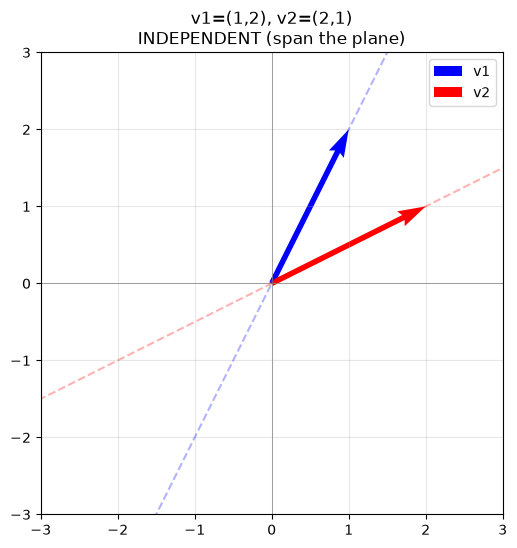

In [4]:
# Independent example
plot_2d([1, 2], [2, 1], "v1=(1,2), v2=(2,1)")

In [5]:
from mpl_toolkits.mplot3d import Axes3D

def plot_3d(v1, v2, title=""):
    v1 = np.array(v1, dtype=float)
    v2 = np.array(v2, dtype=float)
    cross = np.cross(v1, v2)
    dependent = np.linalg.norm(cross) < 1e-9

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection='3d')

    # Lines through origin
    t = np.linspace(-3, 3, 100)
    ax.plot(t*v1[0], t*v1[1], t*v1[2], color='blue', alpha=0.3, linestyle='--')
    ax.plot(t*v2[0], t*v2[1], t*v2[2], color='red',  alpha=0.3, linestyle='--')

    # Arrows
    ax.quiver(0,0,0, *v1, color='blue', arrow_length_ratio=0.1, linewidth=2, label='v1')
    ax.quiver(0,0,0, *v2, color='red',  arrow_length_ratio=0.1, linewidth=2, label='v2')

    # If independent, draw the spanned plane
    if not dependent:
        s = np.linspace(-2, 2, 15)
        u = np.linspace(-2, 2, 15)
        S, U = np.meshgrid(s, u)
        X = S*v1[0] + U*v2[0]
        Y = S*v1[1] + U*v2[1]
        Z = S*v1[2] + U*v2[2]
        ax.plot_surface(X, Y, Z, alpha=0.15, color='green', edgecolor='none')

    all_vals = np.concatenate([v1, v2, [0]])
    m = max(4, 1.3*np.max(np.abs(all_vals)))
    ax.set_xlim(-m, m); ax.set_ylim(-m, m); ax.set_zlim(-m, m)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')

    status = "DEPENDENT (same line)" if dependent else "INDEPENDENT (span a plane)"
    ax.set_title(title + "\n" + status)
    ax.legend()
    plt.show()

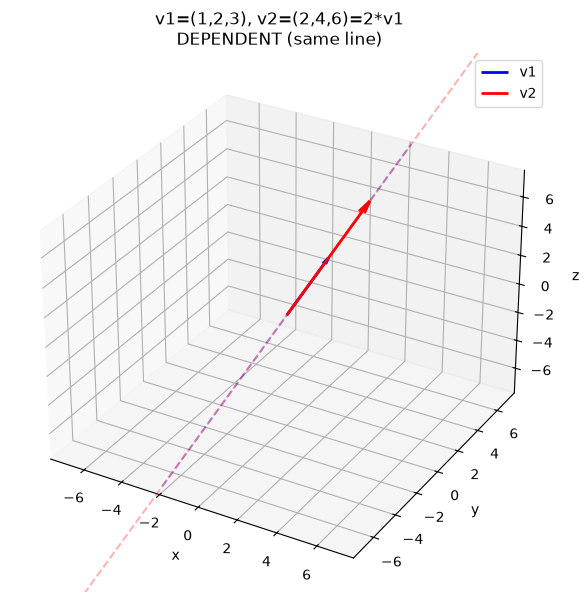

In [6]:
# Dependent
plot_3d([1, 2, 3], [2, 4, 6], "v1=(1,2,3), v2=(2,4,6)=2*v1")

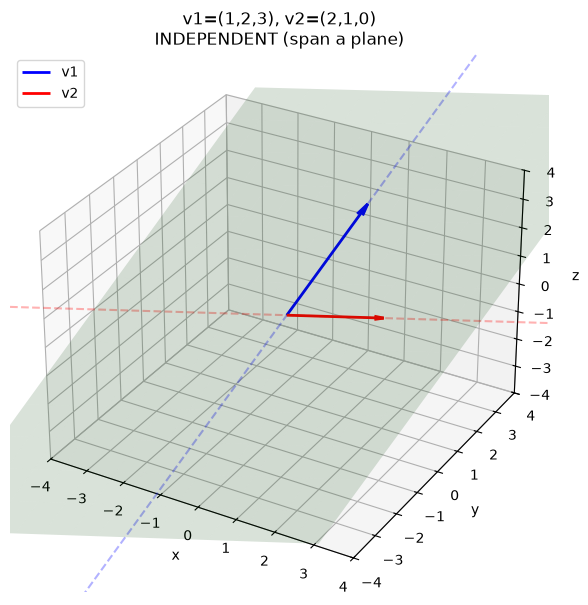

In [7]:
# Independent
plot_3d([1, 2, 3], [2, 1, 0], "v1=(1,2,3), v2=(2,1,0)")

## Problem

Find the condition under which the two vectors

$$
v_1 = \begin{pmatrix} x \\ y \\ 3 \end{pmatrix}, \qquad
v_2 = \begin{pmatrix} 2 \\ x-y \\ 1 \end{pmatrix} \in \mathbb{R}^3
$$

are **linearly independent**.

---

## Recall the definitions

Two vectors $v_1, v_2$ are:

- **Linearly dependent** $\iff$ one is a scalar multiple of the other:
  $$
  v_1 = \lambda v_2 \quad \text{for some } \lambda \in \mathbb{R}.
  $$
  Equivalently, $v_1 \times v_2 = 0$. Geometrically: they lie on the same line through the origin.

- **Linearly independent** $\iff$ they are not scalar multiples:
  $$
  v_1 \neq \lambda v_2 \quad \text{for all } \lambda \in \mathbb{R}.
  $$
  Equivalently, $v_1 \times v_2 \neq 0$. Geometrically: they span a plane through the origin.

---

## Solving by hand

Suppose $v_1 = \lambda v_2$. Comparing third components:

$$
3 = \lambda \cdot 1 \;\Longrightarrow\; \lambda = 3.
$$

Then comparing first components:

$$
x = 3 \cdot 2 = 6.
$$

And comparing second components:

$$
y = 3(x - y) = 3(6 - y) = 18 - 3y
\;\Longrightarrow\; 4y = 18
\;\Longrightarrow\; y = \frac{9}{2}.
$$

So the only way the vectors can be dependent is

$$
(x, y) = \left(6, \tfrac{9}{2}\right).
$$

At that point,

$$
v_1 = \begin{pmatrix} 6 \\ 9/2 \\ 3 \end{pmatrix}
= 3 \begin{pmatrix} 2 \\ 3/2 \\ 1 \end{pmatrix}
= 3\,v_2.
$$

### Answer

$$
\boxed{\,v_1, v_2 \text{ are linearly independent} \iff (x, y) \neq \left(6, \tfrac{9}{2}\right)\,}
$$

Equivalently,

$$
\boxed{\,x \neq 6 \;\text{ or }\; y \neq \tfrac{9}{2}\,}
$$

---

## Verification via the cross product

$$
v_1 \times v_2 =
\begin{vmatrix}
\mathbf{i} & \mathbf{j} & \mathbf{k} \\
x & y & 3 \\
2 & x-y & 1
\end{vmatrix}
=
\begin{pmatrix}
y - 3(x-y) \\
6 - x \\
x(x-y) - 2y
\end{pmatrix}
=
\begin{pmatrix}
4y - 3x \\
6 - x \\
x^2 - xy - 2y
\end{pmatrix}.
$$

For dependence we need $v_1 \times v_2 = 0$, which forces $x = 6$ (second component) and then $4y = 18$, i.e. $y = 9/2$. The same result.

In [8]:

# Build v1(x,y) and v2(x,y), plus the dependence test

def v1_of(x, y):
    return np.array([x, y, 3], dtype=float)

def v2_of(x, y):
    return np.array([2, x - y, 1], dtype=float)

def analyze(x, y):
    v1 = v1_of(x, y)
    v2 = v2_of(x, y)
    cross = np.cross(v1, v2)
    norm_cross = np.linalg.norm(cross)
    dependent = norm_cross < 1e-9

    print(f"x = {x}, y = {y}")
    print("v1 =", v1)
    print("v2 =", v2)
    print("v1 x v2 =", cross)
    print("||v1 x v2|| =", norm_cross)
    print("Result:", "DEPENDENT" if dependent else "INDEPENDENT")
    print("-" * 40)

    plot_3d(v1, v2, f"x={x}, y={y}")
    return dependent

x = 6, y = 4.5
v1 = [6.  4.5 3. ]
v2 = [2.  1.5 1. ]
v1 x v2 = [0. 0. 0.]
||v1 x v2|| = 0.0
Result: DEPENDENT
----------------------------------------


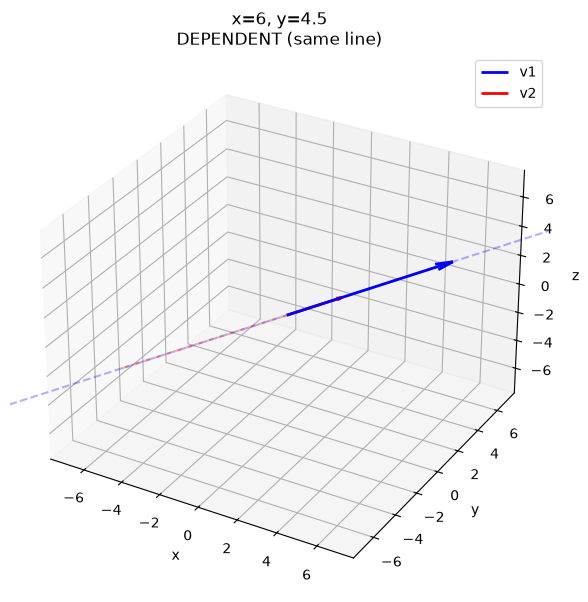

np.True_

In [9]:
# dependent case

analyze(6, 4.5)

x = 1, y = 2
v1 = [1. 2. 3.]
v2 = [ 2. -1.  1.]
v1 x v2 = [ 5.  5. -5.]
||v1 x v2|| = 8.660254037844387
Result: INDEPENDENT
----------------------------------------


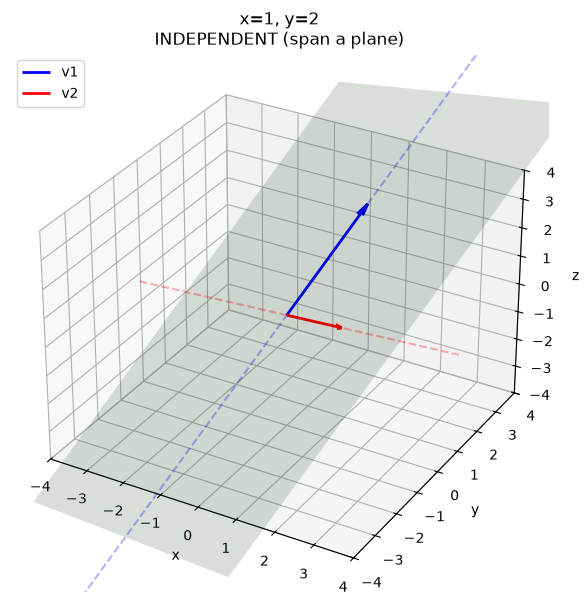

np.False_

In [10]:
# independent case

analyze(1, 2)

x = 6, y = 4.5
v1 = [6.  4.5 3. ]
v2 = [2.  1.5 1. ]
v1 x v2 = [0. 0. 0.]
||v1 x v2|| = 0.0
Result: DEPENDENT
----------------------------------------


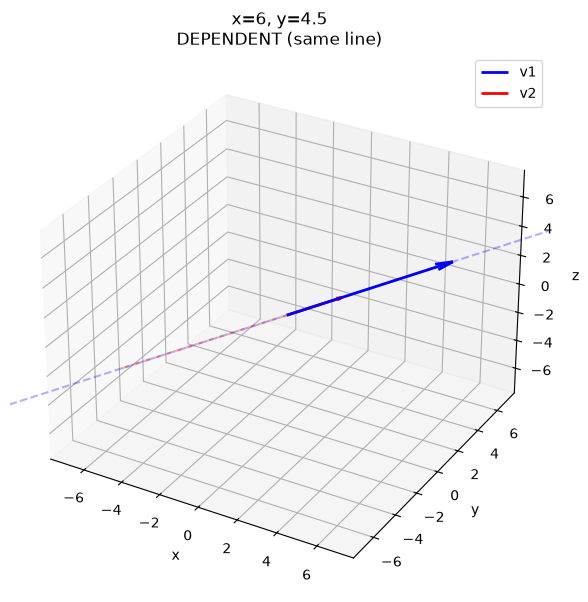

x = 6, y = 0
v1 = [6. 0. 3.]
v2 = [2. 6. 1.]
v1 x v2 = [-18.   0.  36.]
||v1 x v2|| = 40.24922359499622
Result: INDEPENDENT
----------------------------------------


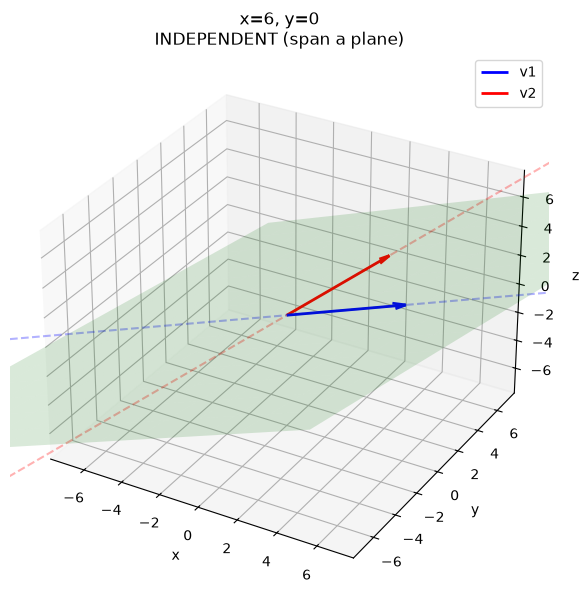

x = 0, y = 4.5
v1 = [0.  4.5 3. ]
v2 = [ 2.  -4.5  1. ]
v1 x v2 = [18.  6. -9.]
||v1 x v2|| = 21.0
Result: INDEPENDENT
----------------------------------------


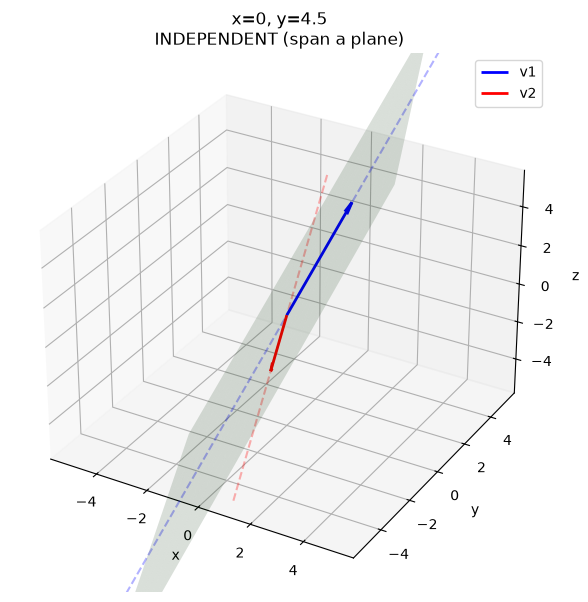

x = 1, y = 1
v1 = [1. 1. 3.]
v2 = [2. 0. 1.]
v1 x v2 = [ 1.  5. -2.]
||v1 x v2|| = 5.477225575051661
Result: INDEPENDENT
----------------------------------------


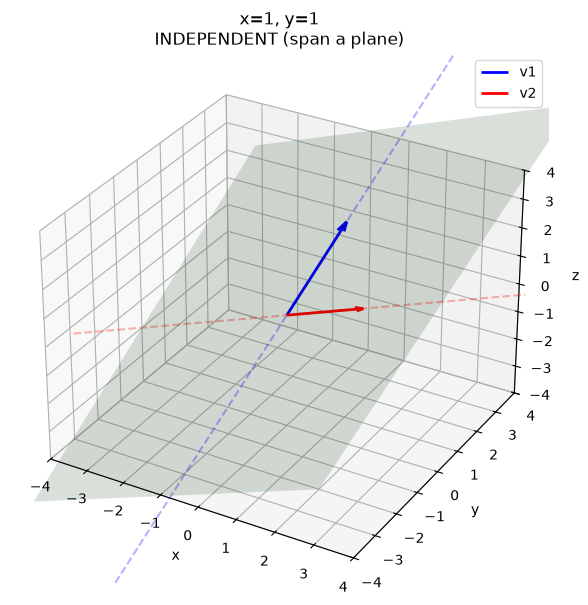

x = 3, y = 3
v1 = [3. 3. 3.]
v2 = [2. 0. 1.]
v1 x v2 = [ 3.  3. -6.]
||v1 x v2|| = 7.3484692283495345
Result: INDEPENDENT
----------------------------------------


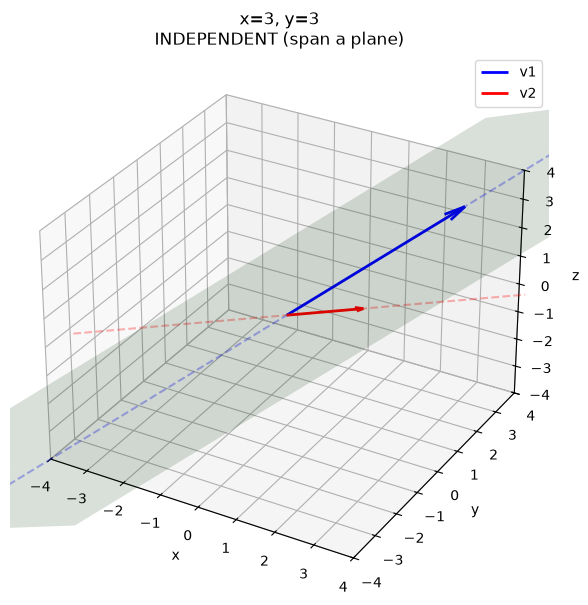

x = -2, y = 7
v1 = [-2.  7.  3.]
v2 = [ 2. -9.  1.]
v1 x v2 = [34.  8.  4.]
||v1 x v2|| = 35.156791662493895
Result: INDEPENDENT
----------------------------------------


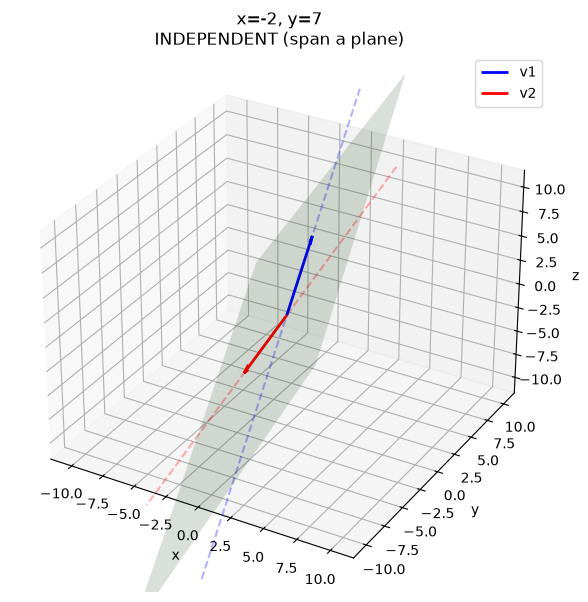

In [11]:
for (x, y) in [(6, 4.5), (6, 0), (0, 4.5), (1, 1), (3, 3), (-2, 7)]:
    analyze(x, y)

In [12]:
from ipywidgets import interact, FloatSlider

interact(
    lambda x, y: analyze(x, y),
    x=FloatSlider(value=1, min=-10, max=10, step=0.25),
    y=FloatSlider(value=2, min=-10, max=10, step=0.25),
)

interactive(children=(FloatSlider(value=1.0, description='x', max=10.0, min=-10.0, step=0.25), FloatSlider(val…

<function __main__.<lambda>(x, y)>

In [13]:
# Scan a grid and find all points where the cross product vanishes
xs = np.linspace(-2, 10, 601)
ys = np.linspace(-2, 10, 601)
dep_points = []
for x in xs:
    for y in ys:
        if np.linalg.norm(np.cross(v1_of(x, y), v2_of(x, y))) < 1e-6:
            dep_points.append((x, y))

# Cluster the found points (they will all be the same point up to grid error)
dep_points = np.array(dep_points)
print("Number of grid points flagged as dependent:", len(dep_points))
print("Mean location:", dep_points.mean(axis=0))

Number of grid points flagged as dependent: 1
Mean location: [6.  4.5]


## Problem

Show that the set of vectors

$$
|v_1\rangle = \begin{pmatrix} 1 \\ 1 \\ 1 \end{pmatrix}, \qquad
|v_2\rangle = \begin{pmatrix} 1 \\ 0 \\ 1 \end{pmatrix}, \qquad
|v_3\rangle = \begin{pmatrix} 1 \\ -1 \\ -1 \end{pmatrix}
$$

is a basis of $\mathbb{C}^3$.

---

## Recall: what it means to be a basis

By **Theorem 1.1**, any set of $n$ linearly independent vectors in $\mathbb{C}^n$ forms a basis of $\mathbb{C}^n$.

So, since we have $n = 3$ vectors in $\mathbb{C}^3$, it is enough to show that they are **linearly independent**.

For three vectors in $\mathbb{C}^3$, a convenient test for independence is the **determinant**:

$$
\det\!\begin{pmatrix} | & | & | \\ v_1 & v_2 & v_3 \\ | & | & | \end{pmatrix}
\neq 0
\;\iff\;
\{v_1, v_2, v_3\} \text{ is linearly independent.}
$$

---

## Compute the determinant

Form the matrix whose columns are $|v_1\rangle, |v_2\rangle, |v_3\rangle$:

$$
M =
\begin{pmatrix}
1 & 1 & 1 \\
1 & 0 & -1 \\
1 & 1 & -1
\end{pmatrix}.
$$

Expand along the first row:

$$
\det M
= 1 \cdot
\begin{vmatrix} 0 & -1 \\ 1 & -1 \end{vmatrix}
- 1 \cdot
\begin{vmatrix} 1 & -1 \\ 1 & -1 \end{vmatrix}
+ 1 \cdot
\begin{vmatrix} 1 & 0 \\ 1 & 1 \end{vmatrix}.
$$

Now compute each $2 \times 2$ determinant:

$$
\begin{vmatrix} 0 & -1 \\ 1 & -1 \end{vmatrix} = (0)(-1) - (-1)(1) = 1,
$$

$$
\begin{vmatrix} 1 & -1 \\ 1 & -1 \end{vmatrix} = (1)(-1) - (-1)(1) = -1 + 1 = 0,
$$

$$
\begin{vmatrix} 1 & 0 \\ 1 & 1 \end{vmatrix} = (1)(1) - (0)(1) = 1.
$$

Therefore,

$$
\det M = 1 \cdot 1 - 1 \cdot 0 + 1 \cdot 1 = 1 + 0 + 1 = 2 \neq 0.
$$

---

## Conclusion

Since $\det M = 2 \neq 0$, the three vectors

$$
|v_1\rangle = \begin{pmatrix} 1 \\ 1 \\ 1 \end{pmatrix}, \quad
|v_2\rangle = \begin{pmatrix} 1 \\ 0 \\ 1 \end{pmatrix}, \quad
|v_3\rangle = \begin{pmatrix} 1 \\ -1 \\ -1 \end{pmatrix}
$$

are linearly independent in $\mathbb{C}^3$.

By **Theorem 1.1**, any set of $3$ linearly independent vectors in $\mathbb{C}^3$ forms a basis. Hence

$$
\boxed{\;\{|v_1\rangle, |v_2\rangle, |v_3\rangle\}\ \text{is a basis of } \mathbb{C}^3.\;}
$$

---

## Alternative check: express a general vector

As a cross-check, any vector $|x\rangle = (a, b, c)^T \in \mathbb{C}^3$ can be written uniquely as

$$
|x\rangle = c_1 |v_1\rangle + c_2 |v_2\rangle + c_3 |v_3\rangle,
$$

which gives the linear system

$$
\begin{cases}
c_1 + c_2 + c_3 = a \\
c_1 - c_3 = b \\
c_1 + c_2 - c_3 = c
\end{cases}
$$

Since the coefficient matrix has determinant $2 \neq 0$, this system has a unique solution for every $(a, b, c)$. This again confirms that $\{|v_1\rangle, |v_2\rangle, |v_3\rangle\}$ spans $\mathbb{C}^3$ and is linearly independent — i.e. a basis.

In [14]:
## Python verification (optional)


import numpy as np

M = np.array([
    [1,  1,  1],
    [1,  0, -1],
    [1,  1, -1],
], dtype=complex)

det = np.linalg.det(M)
rank = np.linalg.matrix_rank(M)

print("Matrix M:\n", M)
print("det(M) =", det)
print("rank(M) =", rank)
print("Linearly independent:", rank == 3)
print("Forms a basis of C^3:", rank == 3 and M.shape[0] == 3)

Matrix M:
 [[ 1.+0.j  1.+0.j  1.+0.j]
 [ 1.+0.j  0.+0.j -1.+0.j]
 [ 1.+0.j  1.+0.j -1.+0.j]]
det(M) = (2+0j)
rank(M) = 3
Linearly independent: True
Forms a basis of C^3: True


### Is it really true about determinant value and its linearity? Need to check by considering such matrices.

In [15]:
def plot_columns(M, name=""):
    """Plot the three columns of a 3x3 matrix as arrows from the origin."""
    M = np.array(M, dtype=float)
    v1, v2, v3 = M[:, 0], M[:, 1], M[:, 2]
    det = np.linalg.det(M)
    dependent = abs(det) < 1e-9

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection='3d')

    ax.quiver(0, 0, 0, *v1, color='blue',  arrow_length_ratio=0.1, linewidth=2, label='col 1')
    ax.quiver(0, 0, 0, *v2, color='red',   arrow_length_ratio=0.1, linewidth=2, label='col 2')
    ax.quiver(0, 0, 0, *v3, color='green', arrow_length_ratio=0.1, linewidth=2, label='col 3')

    # If dependent, shade the plane spanned by col 1 and col 2
    if dependent:
        s = np.linspace(-2, 2, 15)
        u = np.linspace(-2, 2, 15)
        S, U = np.meshgrid(s, u)
        X = S*v1[0] + U*v2[0]
        Y = S*v1[1] + U*v2[1]
        Z = S*v1[2] + U*v2[2]
        ax.plot_surface(X, Y, Z, alpha=0.15, color='orange', edgecolor='none')

    all_vals = np.concatenate([v1, v2, v3, [0]])
    m = max(4, 1.3*np.max(np.abs(all_vals)))
    ax.set_xlim(-m, m); ax.set_ylim(-m, m); ax.set_zlim(-m, m)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')

    status = "DEPENDENT (det = 0)" if dependent else "INDEPENDENT (det != 0)"
    ax.set_title(f"Columns of {name} — {status}\n det = {det:.3f}")
    ax.legend()
    plt.show()


def analyze_matrix(M, name="M"):
    M = np.array(M, dtype=float)
    det = np.linalg.det(M)
    rank = np.linalg.matrix_rank(M)
    n = M.shape[1]
    print(f"Matrix {name}:\n{M}")
    print(f"  det({name}) = {det:.6f}")
    print(f"  rank({name}) = {rank}")
    if rank < n:
        print(f"  -> Columns are LINEARLY DEPENDENT (rank < {n})")
    else:
        print(f"  -> Columns are LINEARLY INDEPENDENT (rank = {n})")
    print("-" * 50)
    return det, rank

Matrix A:
[[1. 2. 3.]
 [2. 4. 6.]
 [1. 1. 2.]]
  det(A) = 0.000000
  rank(A) = 2
  -> Columns are LINEARLY DEPENDENT (rank < 3)
--------------------------------------------------


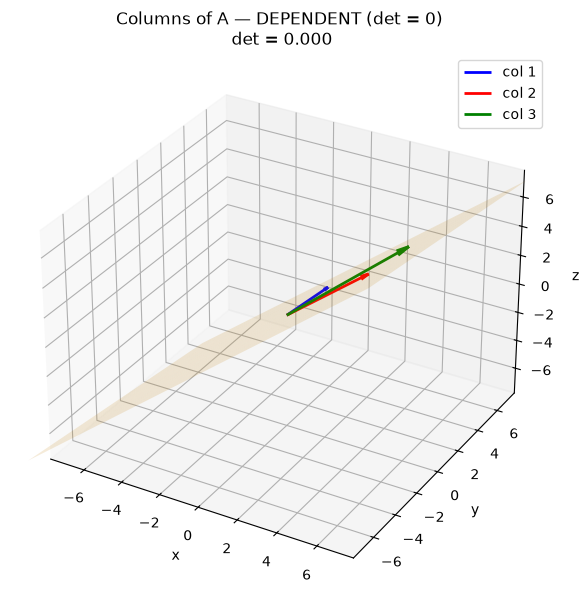

In [16]:
A = np.array([
    [1, 2, 3],
    [2, 4, 6],
    [1, 1, 2],
])

analyze_matrix(A, "A")
plot_columns(A, "A")

Matrix B:
[[ 1.  1.  1.]
 [ 1.  0. -1.]
 [ 1.  1. -1.]]
  det(B) = 2.000000
  rank(B) = 3
  -> Columns are LINEARLY INDEPENDENT (rank = 3)
--------------------------------------------------


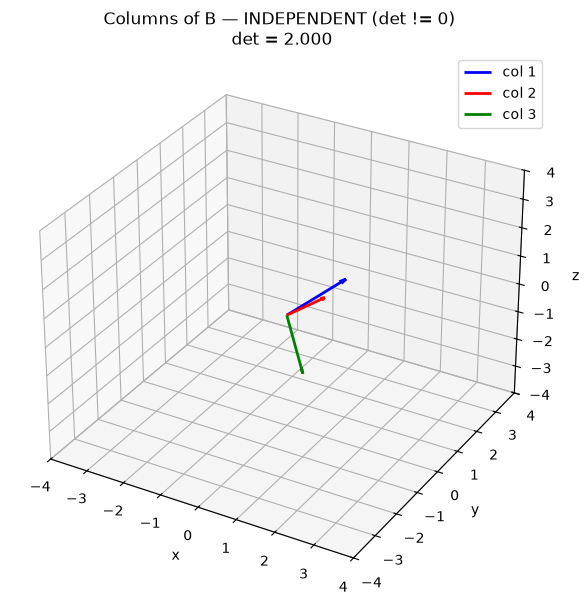

In [17]:
B = np.array([
    [1,  1,  1],
    [1,  0, -1],
    [1,  1, -1],
])

analyze_matrix(B, "B")
plot_columns(B, "B")

### What is given by determinant?
In 2D: two column vectors span a parallelogram. Determinant = area (with sign).

In 3D: three column vectors span a parallelepiped. Determinant = volume (with sign).

In nD: nn column vectors span an nn-dimensional box. Determinant = its nn-volume.

```text
Determinant	Volume	       Meaning
det⁡≠0	     nonzero volume	vectors fill the whole space → independent
det⁡=0	     zero volume	vectors are squashed into a lower dimension → dependent
```

In [18]:
import numpy as np
import matplotlib.pyplot as plt

def plot_parallelogram(M, name=""):
    """Draw the parallelogram spanned by the two columns of a 2x2 matrix."""
    M = np.array(M, dtype=float)
    v1, v2 = M[:, 0], M[:, 1]
    det = np.linalg.det(M)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)

    # Fill the parallelogram spanned by v1, v2
    poly = np.array([[0, 0], v1, v1 + v2, v2])
    ax.fill(poly[:, 0], poly[:, 1], color='orange', alpha=0.3, edgecolor='black')

    # Arrows
    ax.quiver(0, 0, *v1, angles='xy', scale_units='xy', scale=1,
              color='blue', width=0.012, label='col 1')
    ax.quiver(0, 0, *v2, angles='xy', scale_units='xy', scale=1,
              color='red', width=0.012, label='col 2')

    ax.set_title(f"{name}: det = {det:.2f}   (area of shaded region)")
    m = max(3, 1.5*np.max(np.abs(M)))
    ax.set_xlim(-m, m); ax.set_ylim(-m, m)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3); ax.legend()
    plt.show()

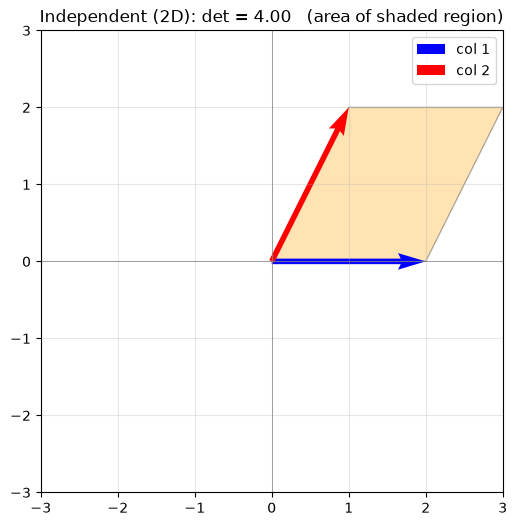

In [19]:
plot_parallelogram([[2, 1], [0, 2]], "Independent (2D)")

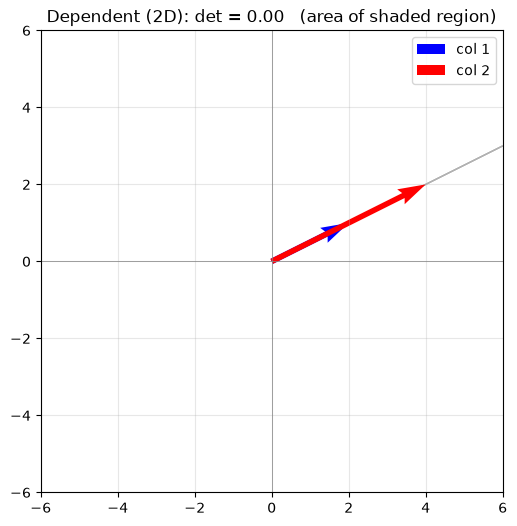

In [20]:
plot_parallelogram([[2, 4], [1, 2]], "Dependent (2D)")

In [21]:
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def plot_parallelepiped(M, name=""):
    M = np.array(M, dtype=float)
    v1, v2, v3 = M[:, 0], M[:, 1], M[:, 2]
    det = np.linalg.det(M)

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection='3d')

    # 8 corners of the parallelepiped: 0, v1, v2, v3, v1+v2, v1+v3, v2+v3, v1+v2+v3
    O = np.zeros(3)
    corners = np.array([
        O, v1, v2, v3,
        v1 + v2, v1 + v3, v2 + v3,
        v1 + v2 + v3,
    ])

    # 6 faces as quads (indices into corners)
    faces = [
        [0, 1, 4, 2],   # spanned by v1, v2
        [0, 1, 5, 3],   # spanned by v1, v3
        [0, 2, 6, 3],   # spanned by v2, v3
        [7, 4, 1, 5],   # opposite of face 1
        [7, 4, 2, 6],   # opposite of face 2
        [7, 5, 3, 6],   # opposite of face 3
    ]
    poly = Poly3DCollection([corners[f] for f in faces],
                            alpha=0.2, facecolor='orange', edgecolor='black')
    ax.add_collection3d(poly)

    # Arrows
    ax.quiver(0, 0, 0, *v1, color='blue',  arrow_length_ratio=0.1, linewidth=2, label='col 1')
    ax.quiver(0, 0, 0, *v2, color='red',   arrow_length_ratio=0.1, linewidth=2, label='col 2')
    ax.quiver(0, 0, 0, *v3, color='green', arrow_length_ratio=0.1, linewidth=2, label='col 3')

    all_vals = np.concatenate([M.ravel(), [0]])
    m = max(4, 1.3*np.max(np.abs(all_vals)))
    ax.set_xlim(-m, m); ax.set_ylim(-m, m); ax.set_zlim(-m, m)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_title(f"{name}: det = {det:.2f}   (volume of the box)")
    ax.legend()
    plt.show()

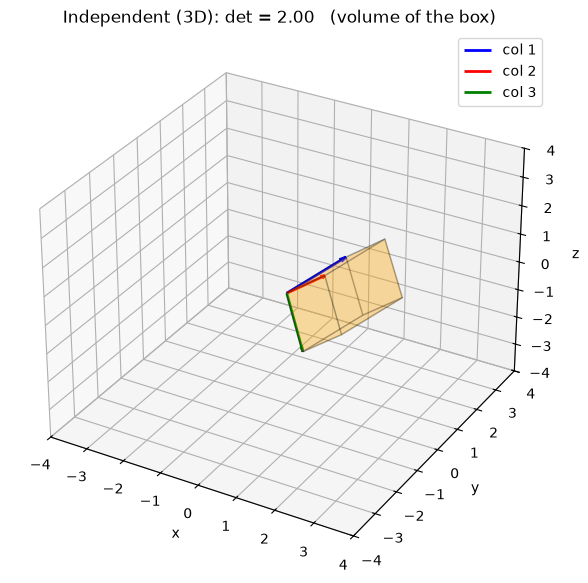

In [22]:
plot_parallelepiped([[1, 1, 1],
                     [1, 0, -1],
                     [1, 1, -1]], "Independent (3D)")

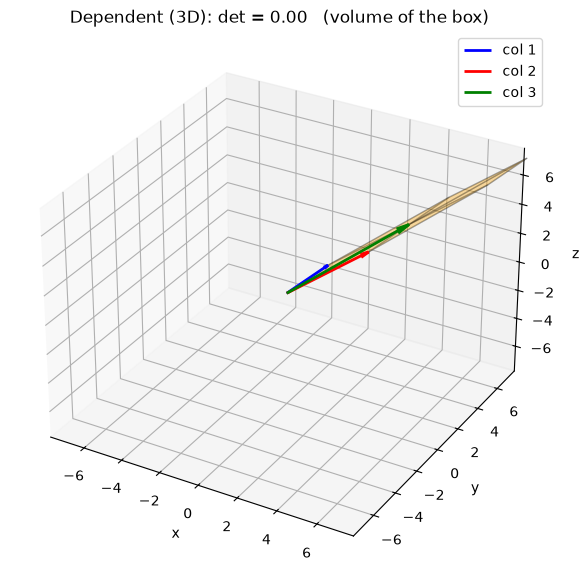

In [23]:
plot_parallelepiped([[1, 2, 3],
                     [2, 4, 6],
                     [1, 1, 2]], "Dependent (3D)")